# Toledano et al. 2024 — разведочный анализ данных readthrough

**Датасет:** Toledano, Supek & Lehner, *Nature Genetics* 2024 — readthrough 5 484 патогенных PTC × 8 препаратов + контроль (HEK293T, DMS sort-seq, контекст ±72 нт).
Источник: figshare «Main dataset» (`treated_samples.rds`), код статьи: [github.com/lehner-lab/Stop_codon_readthrough](https://github.com/lehner-lab/Stop_codon_readthrough).

**Вопросы EDA:** качество данных · различия препаратов · детерминанты readthrough (тип стопа, +4 нт) · что уже измерено для CFTR.

## 1. Загрузка и очистка

pyreadr возвращает категориальные колонки — без `astype(str)` группировка по нескольким ключам строит полное декартово произведение категорий и падает по памяти (поймано на практике). Из 144 колонок оставляем 7 нужных.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pyreadr, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# палитра (dataviz reference, light mode)
SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
SEQ = ["#cde2fb","#b7d3f6","#9ec5f4","#86b6ef","#6da7ec","#5598e7","#3987e5","#2a78d6","#256abf","#1c5cab","#184f95","#104281","#0d366b"]
seq_cmap = LinearSegmentedColormap.from_list("seq", SEQ)
div_cmap  = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})

df = pyreadr.read_r("treated_samples.rds")[None]
df = df[["mutation_identifier", "GENEINFO", "mutation_identifier_short",
         "treatment", "RT", "stop_type", "down_1nt"]]  # ponytail: 144 колонки -> 7, иначе ~1.8 ГБ RAM
for c in df.columns:
    if str(df[c].dtype) == "category":
        df[c] = df[c].astype(str)
df.shape

(105066, 7)

Усредняем репликами: одна строка = пара (вариант × условие).

In [2]:
tidy = (df.groupby(["mutation_identifier", "GENEINFO", "mutation_identifier_short",
                    "treatment"], as_index=False)["RT"].mean())
wide = tidy.pivot(index="mutation_identifier", columns="treatment", values="RT")
DRUGS = [c for c in wide.columns if c != "Untreated"]
order = wide[DRUGS].median().sort_values(ascending=False).index.tolist()
print(f"вариантов: {wide.shape[0]} | условий: {wide.shape[1]}")
tidy.groupby("treatment")["RT"].apply(lambda s: s.isna().sum()).rename("NaN").to_frame().T

вариантов: 5484 | условий: 9


treatment,CC90009,Clitocine,DAP,FUr,G418,Gentamicin,SJ6986,SRI,Untreated
NaN,89,28,33,29,24,38,46,34,40


## 2. Распределение readthrough по препаратам

RT — % экспрессии от WT, шкала логарифмическая (медианы от 0.17% без лечения до 1.5% у clitocine).

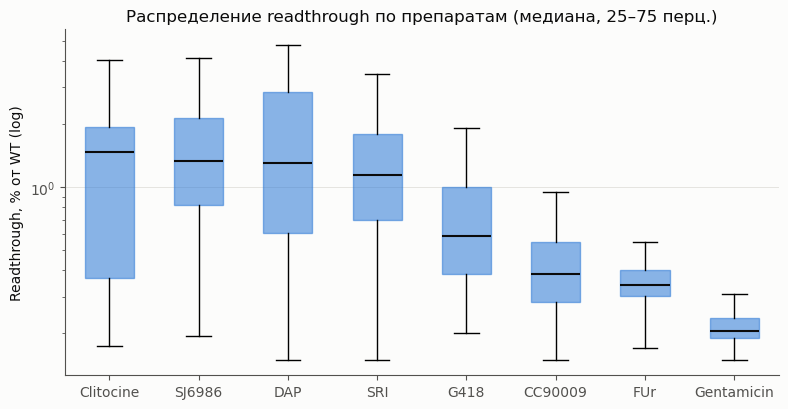

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
bp = ax.boxplot([wide[d].dropna().values for d in order], tick_labels=order,
                showfliers=False, patch_artist=True, medianprops=dict(color=INK, lw=1.5), widths=.55)
for b in bp["boxes"]:
    b.set(facecolor=C1, edgecolor=C1, alpha=.55)
ax.set_yscale("log")
ax.set_ylabel("Readthrough, % от WT (log)")
ax.set_title("Распределение readthrough по препаратам (медиана, 25–75 перц.)")
ax.grid(axis="y", color="#e5e4e0", lw=.7); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("figs/fig1_rt_distribution.png", dpi=150); plt.show()

### Порог «любой препарат» против одного препарата

Порог 2% — операционный ориентир клинической значимости из статьи.

In [4]:
rows = []
for thr in [0.5, 1.0, 2.0]:
    rows.append({
        "порог RT, %": thr,
        "любой препарат": 100 * (wide[DRUGS].max(axis=1) > thr).mean(),
        "только DAP": 100 * (wide["DAP"] > thr).mean(),
        "только Gentamicin": 100 * (wide["Gentamicin"] > thr).mean(),
    })
pd.DataFrame(rows).round(1)

,"порог RT, %",любой препарат,только DAP,только Gentamicin
0,0.5,99.4,84.7,3.4
1,1.0,85.4,54.5,0.7
2,2.0,50.8,38.9,0.0


## 3. Детерминанты: тип стоп-кодона и нуклеотид +4

Признаки, на которых построена модель статьи, видны уже в сырых медианах.

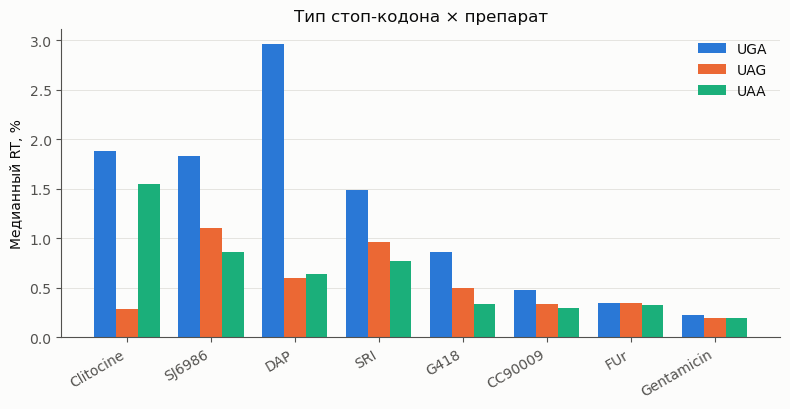

In [5]:
st = df.groupby(["mutation_identifier", "treatment", "stop_type"], as_index=False)["RT"].mean()
med = st.groupby(["treatment", "stop_type"])["RT"].median().unstack()[["uga","uag","uaa"]].loc[order]
x = np.arange(len(med)); w = .26
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, (col, color) in enumerate(zip(["uga","uag","uaa"], [C1, C2, C3])):
    ax.bar(x + (i-1)*w, med[col], w, color=color, label=col.upper())
ax.set_xticks(x, med.index, rotation=30, ha="right")
ax.set_ylabel("Медианный RT, %"); ax.set_title("Тип стоп-кодона × препарат")
ax.legend(frameon=False); ax.grid(axis="y", color="#e5e4e0", lw=.7); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("figs/fig2_stoptype.png", dpi=150); plt.show()

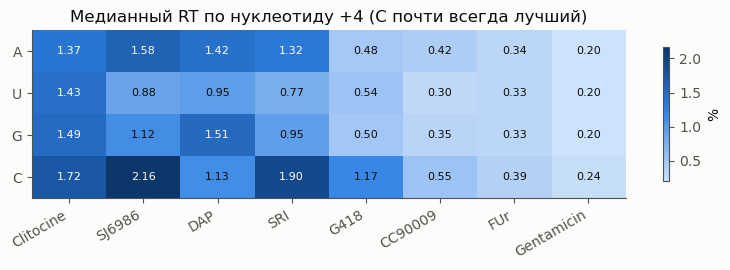

In [6]:
p4 = df.groupby(["mutation_identifier", "treatment", "down_1nt"], as_index=False)["RT"].mean()
h = p4.groupby(["down_1nt", "treatment"])["RT"].median().unstack().loc[["a","u","g","c"], order]
fig, ax = plt.subplots(figsize=(8, 2.8))
im = ax.imshow(h.values, cmap=seq_cmap, aspect="auto")
ax.set_xticks(range(len(order)), order, rotation=30, ha="right")
ax.set_yticks(range(4), [b.upper() for b in h.index])
for i in range(4):
    for j in range(len(order)):
        v = h.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="#ffffff" if v > np.nanmax(h.values)*.6 else INK)
ax.set_title("Медианный RT по нуклеотиду +4 (C почти всегда лучший)")
fig.colorbar(im, ax=ax, shrink=.8, label="%")
fig.tight_layout(); fig.savefig("figs/fig3_plus4nt.png", dpi=150); plt.show()

## 4. Корреляция препаратов

Spearman 0.4–0.8: препараты читают разные подмножества PTC — выбор препарата индивидуален.

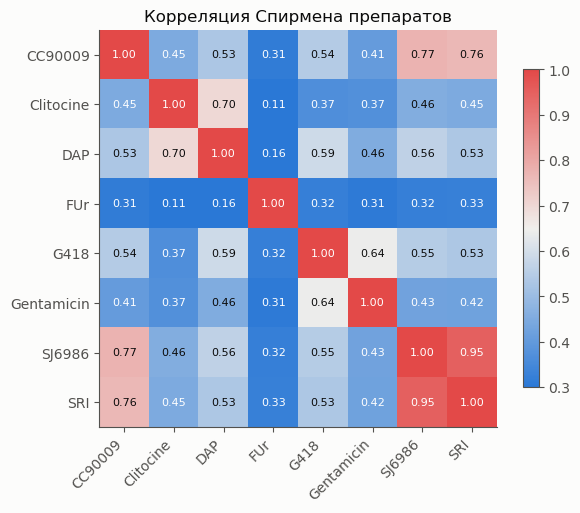

In [7]:
corr = wide[DRUGS].corr("spearman")
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(corr.values, cmap=div_cmap, vmin=0.3, vmax=1)
ax.set_xticks(range(len(DRUGS)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(DRUGS)), corr.columns)
for i in range(len(DRUGS)):
    for j in range(len(DRUGS)):
        ax.text(j, i, f"{corr.values[i,j]:.2f}", ha="center", va="center", fontsize=8,
                color="#ffffff" if (corr.values[i,j] > .85 or corr.values[i,j] < .45) else INK)
ax.set_title("Корреляция Спирмена препаратов")
fig.colorbar(im, ax=ax, shrink=.8)
fig.tight_layout(); fig.savefig("figs/fig4_drug_corr.png", dpi=150); plt.show()

## 5. CFTR: 76 нонсенс-вариантов измерены напрямую

Из 853 нонсенс-вариантов CFTR в ClinVar в библиотеке 76 (~9%) — готовый внутренний тестовый набор. Экспорт: `cftr_readthrough.csv`.

In [8]:
cf = tidy[tidy["GENEINFO"] == "CFTR"]
cfw = cf.pivot(index="mutation_identifier_short", columns="treatment", values="RT")
cfw = cfw.loc[cfw[DRUGS].median(axis=1).sort_values(ascending=False).index]
cfw.round(3).to_csv("cftr_readthrough.csv")
print(f"CFTR вариантов: {cfw.shape[0]} из 853 (ClinVar)")
cfw.head(10).round(2)

CFTR вариантов: 76 из 853 (ClinVar)


treatment,CC90009,Clitocine,DAP,FUr,G418,Gentamicin,SJ6986,SRI,Untreated
mutation_identifier_short,,,,,,,,,
C524X,1.90,2.41,4.40,1.60,3.24,0.64,6.13,5.25,0.39
S1196X,1.24,2.62,4.65,0.63,2.58,0.65,3.25,4.20,0.21
R764X,1.03,2.18,4.06,0.31,0.78,0.21,3.43,3.37,0.18
W19X,0.59,1.66,4.19,0.37,1.52,0.24,2.04,1.67,0.18
S466X,1.05,2.15,2.54,0.31,1.25,0.34,1.78,1.84,0.17
W1282X,0.37,1.89,1.93,0.46,0.91,0.21,2.21,2.12,0.16
R785X,0.69,1.75,2.40,0.40,0.92,0.19,2.27,2.13,0.19
R810X,0.69,1.69,3.99,0.31,0.98,0.25,2.41,2.88,0.16
W1204X,0.94,1.21,2.49,0.34,1.47,0.23,1.55,1.38,0.18


In [9]:
key = cfw.loc[cfw.index.isin(["G542X", "W1282X", "R553X", "S1196X"])]
best = cfw[DRUGS].idxmax(axis=1)
out = pd.DataFrame({
    "лучший RT, %": cfw[DRUGS].max(axis=1).round(2),
    "лучший препарат": best,
}).loc[key.index]
out["RT>2%"] = cfw.loc[key.index, DRUGS].max(axis=1) > 2
out

,"лучший RT, %",лучший препарат,RT>2%
mutation_identifier_short,,,
S1196X,4.65,DAP,True
W1282X,2.21,SJ6986,True
G542X,1.94,DAP,False
R553X,2.56,DAP,True


In [10]:
print("CFTR-вариантов с RT>2% хотя бы одним препаратом:",
      int((cfw[DRUGS].max(axis=1) > 2).sum()), "из", len(cfw))
print("\nКакой препарат чаще всего лучший для CFTR:")
print(best.value_counts().to_dict())

CFTR-вариантов с RT>2% хотя бы одним препаратом: 33 из 76

Какой препарат чаще всего лучший для CFTR:
{'DAP': 33, 'Clitocine': 21, 'SJ6986': 12, 'SRI': 6, 'G418': 4}


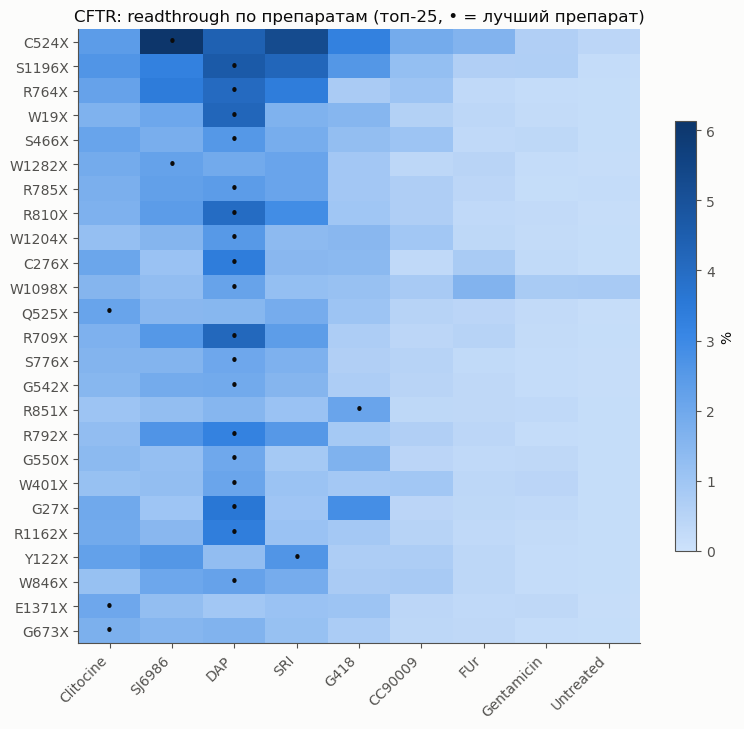

In [11]:
top = cfw.head(25)
fig, ax = plt.subplots(figsize=(8, 7.4))
v = np.ma.masked_invalid(top[[*order, "Untreated"]].values.astype(float))
im = ax.imshow(v, cmap=seq_cmap, aspect="auto", vmin=0, vmax=np.nanmax(v))
ax.set_xticks(range(v.shape[1]), [*order, "Untreated"], rotation=45, ha="right")
ax.set_yticks(range(len(top)), top.index)
for j in range(len(top)):
    k = np.nanargmax(v[j].filled(-np.inf))
    ax.text(k, j, "•", ha="center", va="center", color=INK, fontsize=11)
ax.set_title("CFTR: readthrough по препаратам (топ-25, • = лучший препарат)")
fig.colorbar(im, ax=ax, shrink=.7, label="%")
fig.tight_layout(); fig.savefig("figs/fig5_cftr.png", dpi=150); plt.show()

## 6. Выводы

1. **Данные готовы к моделированию**: 5 484 × 9, пропусков <1%, наша оценка доли вариантов с RT>2% при подборе препарата (50.8%) сходится со статьёй (50.3%).
2. **Препараты разные**: корреляции 0.4–0.8, медианный RT различается в ~7 раз; гентамицин ≈ без лечения.
3. **CFTR**: 76 вариантов измерены; у самых частых мутаций (G542X — 1.9%) резерв именно в подборе/комбинации препаратов. Лучший для CFTR чаще всего DAP (33/76), затем clitocine.
4. **Ниша для работы**: ataluren/ELX-02 в данных нет; модель статьи линейная (elastic net по ±3 нт); 777 нонсенс-вариантов CFTR не измерены — кандидаты на предсказание. Бейзлайн воспроизводить с разбиением по генам (CFTR в тест).